# Step 4: Prepare model input layers

Prepare soil inputs for **CREST** and roughness and climate inputs for **KW**.
Download the source layers, then align them to the final model DEM.
Run from `Example/Example_notebooks` with the **EF5 Builder** kernel.

## 1. Water balance (CREST)

Use **SoilGrids 2017** for this example. It provides the sand, clay, and
bedrock layers needed in Step 7. [SoilGrids details](../../docs/soilgrids.md).


In [1]:
import logging
from pathlib import Path
from ef5_builder import download_soilgrids_2017, download_soilgrids_v2, resample_and_subset
import glob 

logging.basicConfig(level=logging.INFO)


### 1.1 Settings

Set the DEM path and output folders. Keep `version="2017"` for the CREST example.
The DEM defines the download area.


In [6]:
version = "2017"  # "2017" or "v2"

download_dir = Path(f"../posproc_outputs/soilgrids_{version}/native")
aligned_dir = Path(f"../posproc_outputs/soilgrids_{version}/aligned")
download_dir.mkdir(parents=True, exist_ok=True)
aligned_dir.mkdir(parents=True, exist_ok=True)

dem = Path("../data_model/basic/dem.tif")  # defines the download extent and final output grid
properties = ("sand", "clay")  # add "silt" if needed
depths_2017 = ("sl1", "sl2", "sl3", "sl4", "sl5", "sl6", "sl7")
depths_v2 = ("0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm")
include_bedrock = True  # 2017 only; centimetres for CREST
resampling = "nearest"  # matches the C-shell script; "average" or "bilinear" also supported
overwrite = True


### 1.2 Download soil texture and bedrock

Run this cell to download the 15 SoilGrids 2017 layers needed by CREST.
SoilGrids v2 is available for other workflows; using it for CREST requires
adapting the calculation. [Versions and units](../../docs/soilgrids.md).


In [ ]:
if version == "2017":
    downloads = download_soilgrids_2017(
        output_dir=download_dir, dem=dem,
        properties=properties, depths=depths_2017, include_bedrock=include_bedrock,
        overwrite=overwrite,
    )
elif version == "v2":
    downloads = download_soilgrids_v2(
        output_dir=download_dir, dem=dem,
        properties=properties, depths=depths_v2, overwrite=overwrite,
    )
else:
    raise ValueError("version must be 2017 or v2")

print(f"Downloaded {len(downloads)} native SoilGrids layers")
downloads


### 1.3 Align the soil layers to the DEM

Run this cell after downloading. It saves aligned copies in `aligned_dir`.
Use `mask_template=True` to keep the DEM's valid area and `overwrite=True`
when replacing existing outputs. [Resampling options](../../docs/soilgrids.md#align-downloaded-rasters).


In [12]:
soil_grids_files = list(download_dir.glob("*.tif"))

outputs = []

for path in soil_grids_files:
    output = resample_and_subset(
        input_file=path,
        output_file=aligned_dir / path.name,
        template=dem,
        resampling=resampling,
        mask_template=True,
        overwrite=overwrite,
    )
    outputs.append(output)

outputs

[PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/SNDPPT_M_sl5_250m.tif'),
 PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/SNDPPT_M_sl2_250m.tif'),
 PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/CLYPPT_M_sl7_250m.tif'),
 PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/CLYPPT_M_sl1_250m.tif'),
 PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/SNDPPT_M_sl4_250m.tif'),
 PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_ex

### 1.4 Inspect the soil layers

Check that the layers cover your study area. Texture values are percentages;
the 2017 bedrock depth is in centimetres.


File: /home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/soilgrids_2017/aligned/SNDPPT_M_sl5_250m.tif
CRS: EPSG:4326
Shape: (1216, 916)
NoData: -9999.0


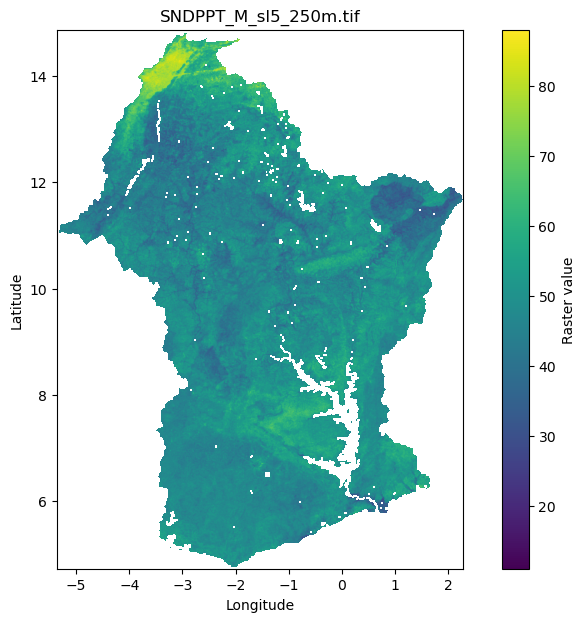

In [19]:
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

path = outputs[0]
with rasterio.open(path) as src:
    print("File:", path)
    print("CRS:", src.crs)
    print("Shape:", src.shape)
    print("NoData:", src.nodata)

path = outputs[0]

with rasterio.open(path) as src:
    data = src.read(1, masked=True)
    extent = plotting_extent(src)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(
    data,
    extent=extent,
    origin="upper",
    cmap="viridis",)
fig.colorbar(im, ax=ax, label="Raster value")
ax.set_title(path.name)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

## 2. Flow routing (KW)

### 2.1 Create Manning roughness from land cover

Place the annual MODIS `LC_Type2` GeoTIFFs in `modis_dir`, then run the cell.
Each land-cover class is assigned a roughness value. The example uses 2001.
[Download instructions and roughness values](../../docs/manning.md).


In [ ]:
from ef5_builder import annual_manning_from_modis

modis_dir = Path("../useful_datasets/modis_2001/")  # path where Modis Geotif files are stored 
annual_n = annual_manning_from_modis(
    input_dir=modis_dir,
    output_dir="../posproc_outputs/manning/",
    file_pattern="MCD12Q1_UMD_*.tif",  # ignores other rasters in the folder
    filename_template=None,  # auto-detect; or "MCD12Q1_UMD_YYYY_Global_*.tif"
    years=None,  # all detected years, with no dataset-date restriction
)
annual_n


### Align Manning roughness to the DEM

Save a copy on the model grid, then inspect the land-cover and roughness maps.


In [4]:
dem = Path("../data_model/basic/dem.tif")
aligned_n = {
    year: resample_and_subset(
        path, f"../posproc_outputs/manning/manning_n_{year}_1km.tif",
        template=dem, mask_template=True,
    )
    for year, path in annual_n.items()
}
aligned_n

{2001: PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/manning/manning_n_2001_1km.tif')}

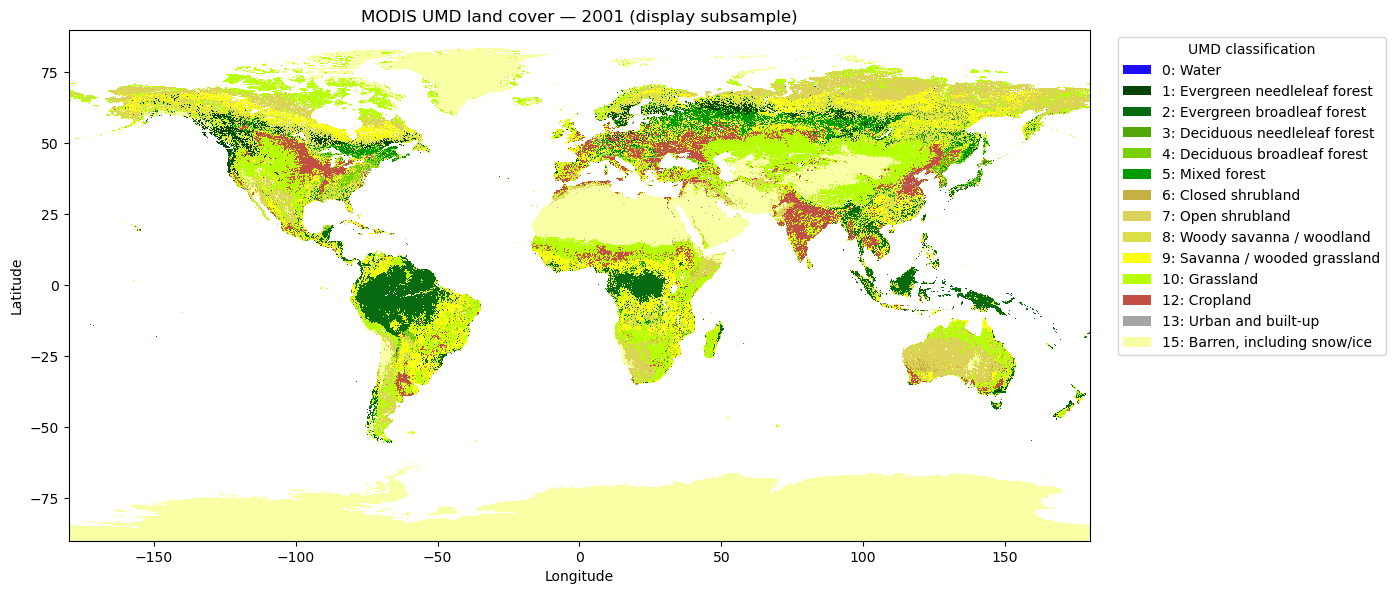

In [5]:
# Visualize the 2001 MODIS LC_Type2 (UMD) global tiles.
from contextlib import ExitStack
from pathlib import Path
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

modis_files = sorted(Path("../useful_datasets/modis_2001").glob("MCD12Q1_UMD_2001_*.tif"))
if not modis_files:
    raise FileNotFoundError("No 2001 MODIS UMD tiles found in ../useful_datasets/modis_2001")

# Match the LC_Type2 legend and palette in earth_engine/export_modis_umd.js.
umd_labels = {
    0: "Water", 1: "Evergreen needleleaf forest", 2: "Evergreen broadleaf forest",
    3: "Deciduous needleleaf forest", 4: "Deciduous broadleaf forest",
    5: "Mixed forest", 6: "Closed shrubland", 7: "Open shrubland",
    8: "Woody savanna / woodland", 9: "Savanna / wooded grassland",
    10: "Grassland", 12: "Cropland", 13: "Urban and built-up",
    15: "Barren, including snow/ice",
}
umd_colors = [
    "#1c0dff", "#05450a", "#086a10", "#54a708", "#78d203", "#009900",
    "#c6b044", "#dcd159", "#dade48", "#fbff13", "#b6ff05", "#808080",
    "#c24f44", "#a5a5a5", "#808080", "#f9ffa4",
]
with ExitStack() as stack:
    sources = [stack.enter_context(rasterio.open(path)) for path in modis_files]
    if any(src.crs != rasterio.crs.CRS.from_epsg(4326) for src in sources):
        raise ValueError("The MODIS plot expects EPSG:4326 exports")
    # Limit the longest display dimension to approximately 2,000 pixels.
    width = max(src.bounds.right for src in sources) - min(src.bounds.left for src in sources)
    height = max(src.bounds.top for src in sources) - min(src.bounds.bottom for src in sources)
    display_resolution = max(abs(sources[0].res[0]), abs(sources[0].res[1]), width / 2000, height / 2000)
    modis_display, modis_transform = merge(
        sources, indexes=[1], res=display_resolution, nodata=255,
        resampling=Resampling.nearest,
    )

landcover = np.ma.masked_where(~np.isin(modis_display[0], list(umd_labels)), modis_display[0])
fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(
    landcover, extent=plotting_extent(landcover, modis_transform), origin="upper",
    cmap=ListedColormap(umd_colors), norm=BoundaryNorm(np.arange(-0.5, 16.5), 16),
    interpolation="nearest",
)
ax.legend(
    handles=[Patch(facecolor=umd_colors[code], label=f"{code}: {label}") for code, label in umd_labels.items()],
    loc="upper left", bbox_to_anchor=(1.02, 1), title="UMD classification",
)
ax.set(title="MODIS UMD land cover — 2001 (display subsample)", xlabel="Longitude", ylabel="Latitude")
fig.tight_layout()
plt.show()


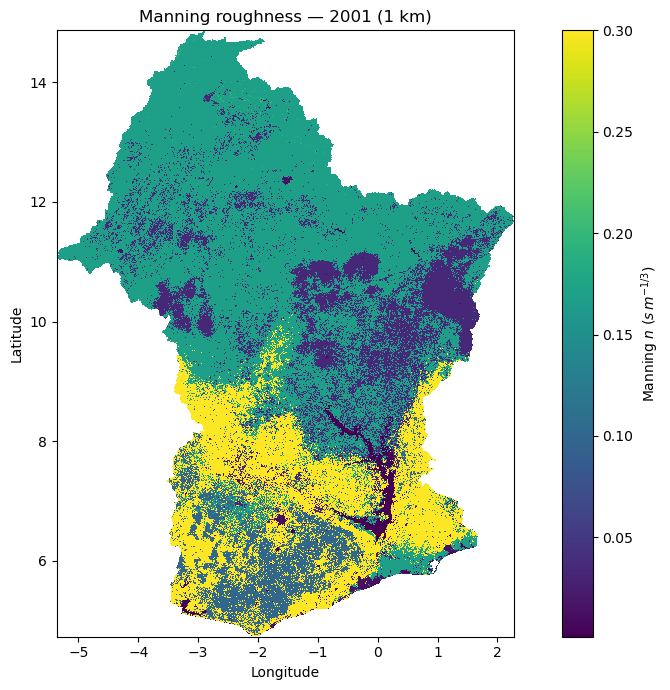

In [6]:
# Visualize the DEM-aligned 2001 Manning roughness raster.
from pathlib import Path
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt

manning_path = Path("../posproc_outputs/manning/manning_n_2001_1km.tif")
with rasterio.open(manning_path) as src:
    manning_data = src.read(1, masked=True)
    manning_extent = plotting_extent(src)
    manning_crs = src.crs

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(manning_data, extent=manning_extent, origin="upper", cmap="viridis", interpolation="nearest")
fig.colorbar(im, ax=ax, label=r"Manning $n$ ($s\,m^{-1/3}$)")
ax.set_title("Manning roughness — 2001 (1 km)")
if manning_crs is not None and manning_crs.is_geographic:
    ax.set(xlabel="Longitude", ylabel="Latitude")
else:
    ax.set(xlabel=f"X coordinate ({manning_crs})", ylabel=f"Y coordinate ({manning_crs})")
fig.tight_layout()
plt.show()


### 2.2 Prepare mean temperature and precipitation

Use the source grids in `Example/useful_datasets/hydromet_files`.
This cell aligns temperature (°C) and annual precipitation (mm/year) to the DEM
and saves them in `basin_integration`. Next, run EF5 `BASIN_AVG` in README Step 6.
Set `hydromet_overwrite=True` to replace existing files.


In [14]:
from pathlib import Path
from ef5_builder import resample_and_subset

hydromet_dir = Path("../useful_datasets/hydromet_files")
basin_integration_dir = Path("../posproc_outputs/basin_integration")
hydromet_dem = Path("../data_model/basic/dem.tif")
hydromet_sources = {
    "mean_temp.tif": hydromet_dir / "africa_temp_avg_30s.tif",
    "mean_precip.tif": hydromet_dir / "africa_precip_avg_mm-y_30s.tif",
}
hydromet_overwrite = False

for path in (hydromet_dem, *hydromet_sources.values()):
    if not path.is_file():
        raise FileNotFoundError(f"Required raster not found: {path}")
if not hydromet_overwrite:
    for filename in hydromet_sources:
        output = basin_integration_dir / filename
        if output.exists():
            raise FileExistsError(f"{output} already exists; set hydromet_overwrite=True to replace outputs.")

basin_integration_dir.mkdir(parents=True, exist_ok=True)
hydromet_outputs = {
    filename: resample_and_subset(
        input_file=source,
        output_file=basin_integration_dir / filename,
        template=hydromet_dem,
        resampling="nearest",
        mask_template=True,
        overwrite=hydromet_overwrite,
    )
    for filename, source in hydromet_sources.items()
}
hydromet_outputs


{'mean_temp.tif': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basin_integration/mean_temp.tif'),
 'mean_precip.tif': PosixPath('/home/vrobledodelgado/LSS/Humberto/Vanessa/FF_climo/phase0_Building_models/EF5-builder-toolkit/Ghana_example/outputs/basin_integration/mean_precip.tif')}